# 07 — Hybrid Recommendation
**Event Recommendation System** · Stage 8

Combine content-based filtering and SVD so each covers the other's blind spot.

## Ways to build a hybrid
| Type | How it works | Example |
|---|---|---|
| **Weighted (static)** | final score = w·CF + (1−w)·CBF, same w for every event | simplest |
| **Switching** | use CBF when CF has no data, otherwise CF | ignores CBF completely once an event has 1 interaction |
| **Confidence-weighted** | the CF weight grows with the event's history | smooth version of switching |
| Feature combination / cascade / meta-level | feed one model's output into another | more complex, more data needed |

### One formula that covers the first three
`final = a_e · CF + (1 − a_e) · CBF`

- **Confidence-weighted** (`k > 0`): `a_e = w · n_e / (n_e + k)`, where `n_e` = training interactions of event e. A new event (`n_e = 0`) gets `a_e = 0` → pure content; with lots of history `a_e → w`. With k = 5, an event with 5 interactions gets half of the maximum CF weight.
- **Static weighted** (`k = 0`): `a_e = w` for every event.
- **Switching**: `w = 1` and a tiny `k` → CF as soon as an event has any history.
- Users with no history are always ranked by content (SVD has no row for them).

Instead of choosing a design by intuition, we put all of them in one grid and **let the validation data decide**.

### Why normalise scores first?
CBF scores are cosine similarities (about 0–1); PureSVD scores can be any size. Before mixing, we **min-max** scale both to 0–1 for each user, so `w` means what we think it means.

### Setup (run this first)
- **In Google Colab** this cell downloads the project from GitHub (data + `src/` code) and moves into it.
- **On your own computer** it just moves from `notebooks/` to the project root.

`sys.path.insert(0, "src")` lets us `import recsys` - the small package that holds the reusable code (cleaning, models, metrics). Notebooks *explain* the code; `src/recsys` *stores* it so every notebook uses exactly the same implementation.

In [1]:
import os, sys, subprocess

REPO_URL = "https://github.com/Abdelrahman2115/recommender-system.git"

if "google.colab" in sys.modules:                       # running inside Google Colab
    if not os.path.exists("/content/recommender-system"):
        subprocess.run(["git", "clone", "-q", REPO_URL, "/content/recommender-system"], check=True)
    os.chdir("/content/recommender-system")
elif os.path.basename(os.getcwd()) == "notebooks":      # running locally from the notebooks folder
    os.chdir("..")

sys.path.insert(0, "src")                               # make `import recsys` work
print("Project root:", os.getcwd())

Project root: /home/claude/recommender-system


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from recsys.data import load_clean, temporal_split, TRAIN_END, VAL_END
from recsys.features import EventFeaturizer
from recsys.models import (ContentBasedRecommender, PureSVDRecommender, FunkSVD, HybridRanker, HybridRatingPredictor,
                           RandomRecommender, PopularityRecommender, GlobalMeanPredictor, minmax)
from recsys.evaluation import make_ranking_task, evaluate_ranking, evaluate_rating, recommend
from recsys.params import load_params, update_params
from recsys.plotting import set_style, bar_labels, MODEL_COLORS, MAIN, TEXT
set_style()

users, events, inter = load_clean()
train, val, test = temporal_split(inter)
P = load_params()                                           # settings chosen in notebooks 05 and 06

cbf = ContentBasedRecommender(
    EventFeaturizer(category_weight=P["cbf"]["category_weight"], city_weight=P["cbf"]["city_weight"]),
    interest_strength=P["cbf"]["interest_strength"], city_strength=P["cbf"]["city_strength"],
    neighbor_shrinkage=P["cbf"]["neighbor_shrinkage"]).fit(train, users, events)
pure = PureSVDRecommender(n_factors=P["pure_svd"]["n_factors"]).fit(train, users, events)
task = make_ranking_task(train, val, events, TRAIN_END, VAL_END)
print("loaded settings:", P)

loaded settings: {'cbf': {'interest_strength': 5.0, 'city_strength': 1.0, 'category_weight': 0.5, 'city_weight': 0.25, 'neighbor_shrinkage': 10.0}, 'svd': {'n_factors': 10, 'reg': 0.02, 'n_epochs': 18, 'lr': 0.01}, 'pure_svd': {'n_factors': 20}}


## 1. The hybrid score for one user, by hand

In [3]:
# pick a user who has history (users without history are ranked by content only)
uid = next(u for u in task.relevant if pure.has_history(u))
cands = np.array([e for e in task.candidates if e not in task.seen.get(uid, set())])
n_e = train.groupby("event_id").size().reindex(cands).fillna(0).to_numpy()

w, k = 0.6, 5                                  # example values (confidence-weighted)
s_cb = minmax(cbf.score(uid, cands))          # content scores scaled to 0-1
s_cf = minmax(pure.score(uid, cands))         # SVD scores scaled to 0-1
a = w * n_e / (n_e + k)                       # per-event trust in SVD
final = a * s_cf + (1 - a) * s_cb

check = HybridRanker(cbf, pure, cf_weight=w, confidence_k=k).fit(train).score(uid, cands)
print("matches recsys.HybridRanker:", np.allclose(final, check))

table = pd.DataFrame({"event_id": cands, "history n_e": n_e.astype(int), "SVD weight a_e": a.round(2),
                      "CBF (0-1)": s_cb.round(2), "SVD (0-1)": s_cf.round(2), "hybrid": final.round(3)})
table.sort_values("hybrid", ascending=False).head(8)

matches recsys.HybridRanker: True


,event_id,history n_e,SVD weight a_e,CBF (0-1),SVD (0-1),hybrid
53,605,32,0.52,1.00,1.00,1.000
66,737,0,0.00,0.98,0.04,0.982
23,317,0,0.00,0.92,0.04,0.921
33,440,0,0.00,0.86,0.04,0.856
35,448,0,0.00,0.82,0.04,0.819
29,389,0,0.00,0.79,0.04,0.788
34,446,0,0.00,0.73,0.04,0.731
65,736,45,0.54,0.61,0.82,0.722


Events with no history have `a_e = 0`, so their hybrid score is their content score. Events with history get a mix.

Notice the **SVD (0-1)** column: after min-max scaling, events with no history get an SVD score near 0, while events with history get higher values. Keep this in mind for section 3.

## 2. Tuning `w` and `k` on validation (k = 0 means static weighting)

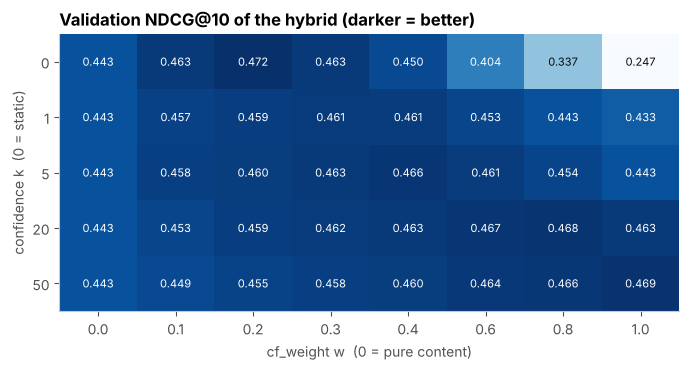

best: {'cf_weight': 0.2, 'confidence_k': 0.0, 'ndcg@10': 0.47192715499671756}


In [4]:
rows = []
for w_ in [0.0, 0.1, 0.2, 0.3, 0.4, 0.6, 0.8, 1.0]:
    for k_ in [0, 1, 5, 20, 50]:
        m = HybridRanker(cbf, pure, cf_weight=w_, confidence_k=k_).fit(train)
        r = evaluate_ranking(m, task).mean(numeric_only=True)
        rows.append({"cf_weight": w_, "confidence_k": k_, "recall@10": r["recall@10"], "ndcg@10": r["ndcg@10"]})
hyb_grid = pd.DataFrame(rows)
best_h = hyb_grid.sort_values("ndcg@10", ascending=False).iloc[0]

pv = hyb_grid.pivot(index="confidence_k", columns="cf_weight", values="ndcg@10")
fig, ax = plt.subplots(figsize=(8, 3.6))
im = ax.imshow(pv.values, cmap="Blues", aspect="auto")
ax.set_xticks(range(pv.shape[1]), pv.columns); ax.set_yticks(range(pv.shape[0]), pv.index)
ax.set_xlabel("cf_weight w  (0 = pure content)"); ax.set_ylabel("confidence k  (0 = static)"); ax.grid(False)
for i in range(pv.shape[0]):
    for j in range(pv.shape[1]):
        ax.text(j, i, f"{pv.values[i, j]:.3f}", ha="center", va="center", fontsize=8,
                color="white" if (pv.values[i, j] - pv.values.min()) / np.ptp(pv.values) > 0.5 else "#0b0b0b")
ax.set_title("Validation NDCG@10 of the hybrid (darker = better)")
plt.show()
print("best:", best_h[["cf_weight", "confidence_k", "ndcg@10"]].to_dict())

**Reading the heatmap:** the left column (w = 0) is pure content-based filtering. Adding some SVD helps in every row. In the top row (static) the best weight is small and larger weights hurt again; the confidence-weighted rows tolerate larger `w` because new events are protected by `n_e/(n_e+k)`.

## 3. Comparing the designs
Best setting of each design on validation, plus a **bootstrap confidence interval** for the difference: we resample the evaluated users 1,000 times and look at the spread of the NDCG difference. If the 95% interval contains 0, the difference could easily be luck.

In [5]:
from recsys.evaluation import bootstrap_ci

static = hyb_grid[hyb_grid["confidence_k"] == 0].sort_values("ndcg@10", ascending=False).iloc[0]
conf = hyb_grid[hyb_grid["confidence_k"] > 0].sort_values("ndcg@10", ascending=False).iloc[0]
designs = {
    "Content-Based only": cbf,
    f"Switching": HybridRanker(cbf, pure, cf_weight=1.0, confidence_k=1e-9).fit(train),
    f"Static weighted (w={static['cf_weight']})": HybridRanker(cbf, pure, static["cf_weight"], 0).fit(train),
    f"Confidence-weighted (w={conf['cf_weight']}, k={int(conf['confidence_k'])})":
        HybridRanker(cbf, pure, conf["cf_weight"], conf["confidence_k"]).fit(train),
}
design_res = {name: evaluate_ranking(m, task).set_index("user_id")["ndcg@10"] for name, m in designs.items()}
best_name = max(design_res, key=lambda n: design_res[n].mean())

rows = []
for name, scores in design_res.items():
    lo, hi = bootstrap_ci(scores - design_res["Content-Based only"])
    rows.append({"design": name, "validation NDCG@10": scores.mean(), "vs content-only: 95% CI": f"[{lo:+.4f}, {hi:+.4f}]"})
table = pd.DataFrame(rows).set_index("design")
names = list(design_res)
lo, hi = bootstrap_ci(design_res[names[2]] - design_res[names[3]])
print(f"static minus confidence-weighted: 95% CI [{lo:+.4f}, {hi:+.4f}]")
table.round(4)

static minus confidence-weighted: 95% CI [-0.0083, +0.0136]


,validation NDCG@10,vs content-only: 95% CI
design,,
Content-Based only,0.4431,"[+0.0000, +0.0000]"
Switching,0.4291,"[-0.0279, -0.0001]"
Static weighted (w=0.2),0.4719,"[+0.0185, +0.0395]"
"Confidence-weighted (w=1.0, k=50)",0.4692,"[+0.0172, +0.0348]"


**Reading the table:**
- **Switching is worse than content alone** — once an event has even one interaction it trusts SVD completely, and SVD factors built from one or two interactions are noise.
- **Both weighted designs beat content-only**, and the confidence intervals of their gain over content-only lie above 0, so the improvement is not luck.
- **Static vs confidence-weighted is a tie**: the interval for their difference contains 0. We keep the one with the higher validation score, as decided in advance.

**Why does the static blend work even though SVD knows nothing about new events?** As noted in section 1, min-max scaling gives new events an SVD score near 0. So a small fixed SVD weight does two things at once: it adds SVD's opinion on events with history, *and* it gently promotes events that already have some activity — events other people have noticed are more likely to be attended. It acts like a mild, personalised popularity signal.

## 4. Who benefits? Validation results for every model

In [6]:
hybrid = HybridRanker(cbf, pure, cf_weight=float(best_h["cf_weight"]), confidence_k=float(best_h["confidence_k"])).fit(train)
print("chosen hybrid:", best_h[["cf_weight", "confidence_k"]].to_dict())
models = {"Random": RandomRecommender(), "Popularity": PopularityRecommender().fit(train),
          "Content-Based": cbf, "SVD": pure, "Hybrid": hybrid}
per_user = {name: evaluate_ranking(m, task) for name, m in models.items()}
val_table = pd.DataFrame({k: v.mean(numeric_only=True) for k, v in per_user.items()}).T[["precision@10", "recall@10", "ndcg@10"]]
val_table.round(4)

chosen hybrid: {'cf_weight': 0.2, 'confidence_k': 0.0}


,precision@10,recall@10,ndcg@10
Random,0.0253,0.1236,0.0637
Popularity,0.0379,0.2010,0.1379
Content-Based,0.1354,0.7148,0.4431
SVD,0.0494,0.2561,0.2117
Hybrid,0.1371,0.7227,0.4719


users per segment: 333 new / 748 active


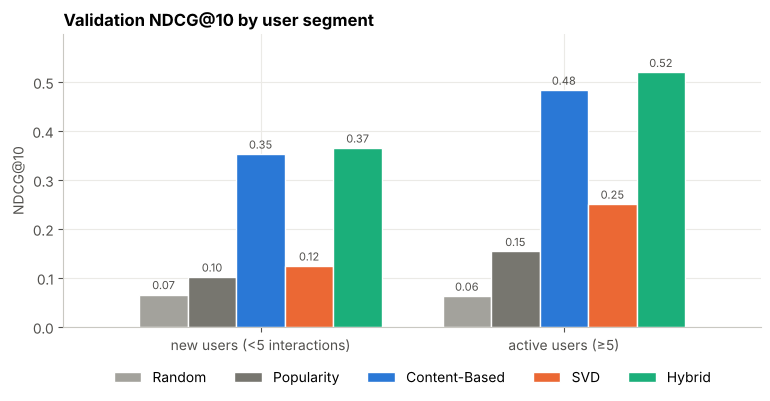

In [7]:
n_user_hist = train.groupby("user_id").size()
rows = []
for name, res in per_user.items():
    hist = res["user_id"].map(n_user_hist).fillna(0)
    rows.append({"model": name,
                 "new users (<5 interactions)": res.loc[hist < 5, "ndcg@10"].mean(),
                 "active users (≥5)": res.loc[hist >= 5, "ndcg@10"].mean()})
seg = pd.DataFrame(rows).set_index("model")
print("users per segment:", (per_user["Hybrid"]["user_id"].map(n_user_hist).fillna(0) < 5).sum(), "new /",
      (per_user["Hybrid"]["user_id"].map(n_user_hist).fillna(0) >= 5).sum(), "active")

ax = seg.T.plot.bar(color=[MODEL_COLORS[m] for m in seg.index], width=0.8, figsize=(9, 3.8), rot=0, edgecolor="white", linewidth=1)
bar_labels(ax, fmt="{:.2f}")
ax.set_ylim(0, seg.values.max() * 1.15); ax.set_ylabel("NDCG@10")
ax.legend(ncols=5, loc="upper center", bbox_to_anchor=(0.5, -0.1))
ax.set_title("Validation NDCG@10 by user segment")
plt.show()

**Reading the chart:** for new users the gain is small (users with zero history are ranked by content only, and users with 1–4 interactions give SVD little to work with). The larger gain comes from **active users**, where SVD adds information from similar users. Popularity and SVD alone do poorly for new users, which is why neither could be the only model.

## 5. Hybrid for rating prediction
For ratings we use a plain weighted blend: `w · SVD + (1 − w) · CBF`. (Unlike ranking, SVD stays useful on brand-new events here: its user bias — is this person a generous or a harsh rater? — does not need the event's history.)

In [8]:
rated_train, rated_val = train.dropna(subset=["rating"]), val.dropna(subset=["rating"])
svd = FunkSVD(n_factors=P["svd"]["n_factors"], reg=P["svd"]["reg"], n_epochs=P["svd"]["n_epochs"]).fit(rated_train)

rows = [{"svd_weight": w_, **evaluate_rating(HybridRatingPredictor(cbf, svd, svd_weight=w_), rated_val)}
        for w_ in [0.0, 0.25, 0.5, 0.75, 1.0]]
rate_grid = pd.DataFrame(rows)
best_rw = float(rate_grid.sort_values("RMSE").iloc[0]["svd_weight"])
print("global-mean RMSE for reference:", round(evaluate_rating(GlobalMeanPredictor().fit(rated_train), rated_val)["RMSE"], 4))
rate_grid.round(4)

global-mean RMSE for reference: 1.0223


,svd_weight,MAE,RMSE
0,0.00,0.8240,0.9988
1,0.25,0.8212,0.9951
2,0.50,0.8194,0.9923
3,0.75,0.8192,0.9905
4,1.00,0.8197,0.9897


**An honest result:** for ratings, validation picks the weight that leans fully (or almost fully) on SVD — adding content-based predictions does not reduce the error further. The two models make similar mistakes on ratings (both mainly learn the user's rating habit), so blending them adds little. We keep the tuned weight, which means **the rating "hybrid" is effectively SVD**. The hybrid's real value is in **ranking**, where the two models see different things.

## 6. Save the chosen settings

In [9]:
params = update_params({"hybrid": {"cf_weight": float(best_h["cf_weight"]), "confidence_k": float(best_h["confidence_k"])},
                        "hybrid_rating": {"svd_weight": best_rw}})
{k: params[k] for k in ["hybrid", "hybrid_rating"]}

{'hybrid': {'cf_weight': 0.2, 'confidence_k': 0.0}, 'hybrid_rating': {'svd_weight': 1.0}}

### Interview questions for this stage
- *Why a hybrid?* — Content-based handles new events and new users; collaborative filtering captures tastes shared by similar users. Events are mostly new, so we need content, but CF adds a second, independent signal where history exists.
- *Why not just a switching hybrid?* — It trusts CF fully after a single interaction, when CF's factors are still noise. Our validation shows it performs worse than content alone.
- *How do you know the hybrid's gain is real?* — A bootstrap over users gives a 95% confidence interval for the improvement over content-only that lies above zero; the difference between the two weighted designs does not, so we call them tied.
- *Why normalise before blending?* — The models' scores are on different scales; without normalisation the weight would not mean what it says.
- *How did you choose the weights?* — Grid search on the **validation** period only; the test period is untouched until the final evaluation.

**Next:** `08_evaluation_and_conclusions.ipynb` — final test-set results.